# Part 2: Bayes' Theorem on IMDb Reviews

We pick some words and work out how likely a review is to be positive when it contains that word.
We use P(Positive | keyword). We do not calculate P(Negative | keyword).

Formula:

P(Positive | keyword) = P(keyword | Positive) x P(Positive) / P(keyword)

- Prior = P(Positive): share of all reviews that are positive
- Likelihood = P(keyword | Positive): share of positive reviews that contain the word
- Marginal = P(keyword): share of all reviews that contain the word
- Posterior = P(Positive | keyword): the answer

## Our keywords

- Positive: excellent, wonderful, masterpiece, brilliant
- Negative: worst, awful, boring, waste

## Why we chose these words

We picked 4 positive words and 4 negative words. We chose words that people use when they clearly like or dislike a film. We did not pick words like "good" or "great" because people also write "not good" and "not great" in bad reviews.

Positive words
- excellent: people use it to praise the acting, the story or the whole film. 81% of the reviews with this word are positive.
- wonderful: people use it when they enjoyed a film. 81% of the reviews with this word are positive.
- masterpiece: it is the highest praise a reviewer can give. It is a rare word, but 73% of the reviews with it are positive.
- brilliant: people use it for good acting, writing or ideas. 76% of the reviews with this word are positive.

Negative words
- worst: people use it when they really disliked a film, like "the worst movie". Only 9% of the reviews with this word are positive.
- awful: people use it for bad acting, bad story or a bad film. Only 10% are positive.
- boring: it is a very common complaint about a film. 19% are positive, which is the highest of our negative words. Some reviewers may write "not boring", so we would expect a few positive reviews to use it.
- waste: it is used in phrases like "waste of time" and "waste of money". Only 7% are positive.

## How we calculated the four probabilities

1. Prior, P(Positive): we counted the positive reviews and divided by all reviews. It is 0.5 because half of the 50,000 reviews are positive.
2. Likelihood, P(keyword | Positive): we counted the positive reviews that contain the word and divided by the number of positive reviews.
3. Marginal, P(keyword): we counted all the reviews that contain the word (positive and negative) and divided by all reviews.
4. Posterior, P(Positive | keyword): we put the three numbers above into Bayes' Theorem: likelihood x prior / marginal.

A review counts as containing a word if the word appears in it at least once. We checked our answers by counting directly (positive reviews with the word / all reviews with the word), and they matched for all 8 words.

In [9]:
import csv
import re

file_name = "IMDB Dataset.csv"
positive_words = ["excellent", "wonderful", "masterpiece", "brilliant"]
negative_words = ["worst", "awful", "boring", "waste"]

## Load the reviews

In [10]:
def load_reviews(file_name):
    """Read the csv. Each review becomes (set of its words, True if positive)."""
    reviews = []
    with open(file_name, newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            text = row["review"].lower().replace("<br />", " ")
            words = set(re.findall(r"[a-z']+", text))
            reviews.append((words, row["sentiment"] == "positive"))
    return reviews

reviews = load_reviews(file_name)
print(len(reviews), "reviews loaded")

50000 reviews loaded


## Calculate the four probabilities

A review counts as containing the word if the word appears in it at least once.

In [11]:
def bayes(reviews, word):
    total = len(reviews)
    positive = sum(1 for words, is_pos in reviews if is_pos)
    with_word = sum(1 for words, is_pos in reviews if word in words)
    positive_with_word = sum(1 for words, is_pos in reviews if is_pos and word in words)

    prior = positive / total
    likelihood = positive_with_word / positive
    marginal = with_word / total
    posterior = likelihood * prior / marginal
    return prior, likelihood, marginal, posterior


def show_table(words_list):
    print("Keyword      Prior   Likelihood  Marginal  Posterior")
    for word in words_list:
        prior, likelihood, marginal, posterior = bayes(reviews, word)
        print(f"{word:<12} {prior:.4f}  {likelihood:.4f}      {marginal:.4f}    {posterior:.4f}")

In [12]:
print("Positive keywords")
show_table(positive_words)
print()
print("Negative keywords")
show_table(negative_words)

Positive keywords
Keyword      Prior   Likelihood  Marginal  Posterior
excellent    0.5000  0.1146      0.0710    0.8073
wonderful    0.5000  0.0902      0.0555    0.8120
masterpiece  0.5000  0.0350      0.0240    0.7300
brilliant    0.5000  0.0634      0.0417    0.7606

Negative keywords
Keyword      Prior   Likelihood  Marginal  Posterior
worst        0.5000  0.0164      0.0886    0.0924
awful        0.5000  0.0112      0.0575    0.0977
boring       0.5000  0.0236      0.0610    0.1938
waste        0.5000  0.0070      0.0507    0.0687


## Check: count directly

The posterior should equal (positive reviews with the word) / (all reviews with the word).

In [13]:
for word in positive_words + negative_words:
    with_word = [is_pos for words, is_pos in reviews if word in words]
    direct = sum(with_word) / len(with_word)
    print(word, round(direct, 4), round(bayes(reviews, word)[3], 4))

excellent 0.8073 0.8073
wonderful 0.812 0.812
masterpiece 0.73 0.73
brilliant 0.7606 0.7606
worst 0.0924 0.0924
awful 0.0977 0.0977
boring 0.1938 0.1938
waste 0.0687 0.0687


## Chart

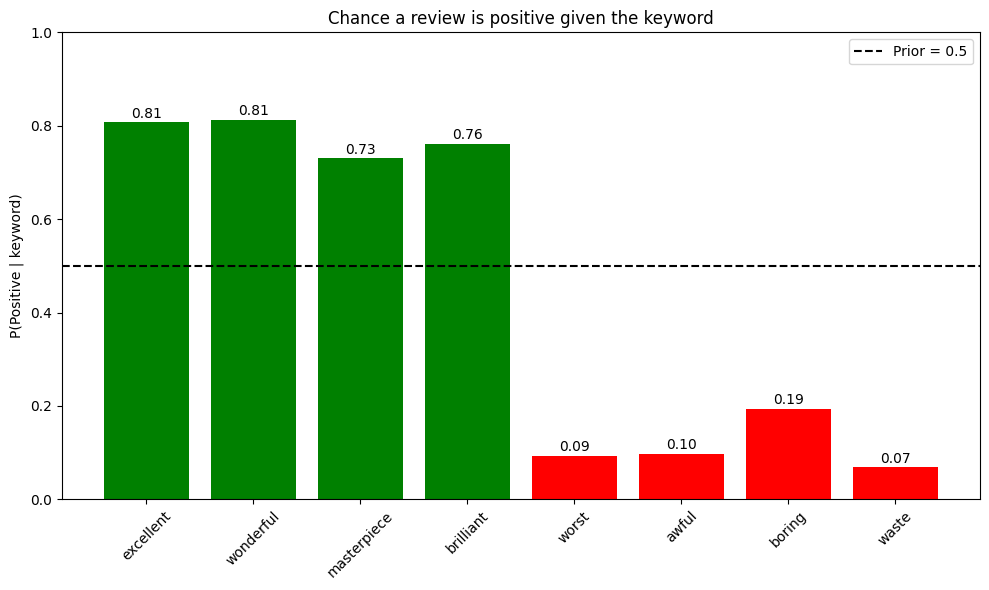

In [15]:
import matplotlib.pyplot as plt

all_words = positive_words + negative_words
posteriors = [bayes(reviews, w)[3] for w in all_words]
colors = ["green"] * len(positive_words) + ["red"] * len(negative_words)

plt.figure(figsize=(10, 6))
bars = plt.bar(all_words, posteriors, color=colors)
plt.axhline(0.5, linestyle="--", color="black", label="Prior = 0.5")

for bar, value in zip(bars, posteriors):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 0.01,
             f"{value:.2f}", ha="center")

plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.ylabel("P(Positive | keyword)")
plt.title("Chance a review is positive given the keyword")
plt.legend()
plt.tight_layout()
plt.show()

## What we see

- The prior is 0.5 because half the reviews are positive and half are negative.
- The positive words give a posterior well above 0.5 (about 0.73 to 0.81).
- The negative words give a posterior well below 0.5 (about 0.07 to 0.19), because almost all reviews containing them are negative.
- "masterpiece" is lower than "excellent" because it also shows up in some negative reviews, for example "not a masterpiece".